# Câu 1 (2,0 điểm): Thu thập và phân tích dữ liệu — Phần 1: Phân tích bộ dữ liệu & Thống kê mô tả

**Mục tiêu:**
1. Tải và kiểm chứng cấu trúc bộ dữ liệu được giao (`cosmos98/twitter-and-reddit-sentimental-analysis-dataset`) cùng bộ dữ liệu huấn luyện có nhãn phân biệt chủng tộc / giới tính (`tweets-hate-speech-detection`, hướng tiếp cận kết hợp dữ liệu chuẩn) và bộ kiểm tra chéo miền (`Davidson et al.`).
2. Thực hiện đầy đủ 10 phân tích thống kê mô tả và kiểm định giả thuyết (Mann-Whitney U, Chi-Square $\chi^2$, Smoothed Log-Odds Ratio, Jaccard Similarity).
3. Toàn bộ từ nhạy cảm / từ tục được che tự động bằng `mask_profanity` trước khi hiển thị.

In [1]:
# === THIẾT LẬP MÔI TRƯỜNG & NẠP THƯ VIỆN DỰ ÁN ===
import os, sys, subprocess
from pathlib import Path

os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
REPO_URL = "https://github.com/nhungoc-1/DoAnKHDL_DeTai_Tweet-Hate.git"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    print("[SETUP] Đang khởi tạo môi trường Google Colab...", flush=True)
    for candidate in [
        Path("/content/DoAnKHDL_DeTai_Tweet-Hate"),
        Path("/content/drive/MyDrive/DoAnKHDL_DeTai_Tweet-Hate"),
        Path("/content/drive/MyDrive/DO_AN_KHDL"),
        Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd(),
    ]:
        if (candidate / "config.yaml").exists():
            PROJECT_DIR = candidate
            subprocess.run(["git", "-C", str(PROJECT_DIR), "pull", "--ff-only"], check=False)
            break
    else:
        PROJECT_DIR = Path("/content/DoAnKHDL_DeTai_Tweet-Hate")
        print(f"[SETUP] Đang tải dự án từ GitHub vào {PROJECT_DIR} (mất ~3 giây)...", flush=True)
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(PROJECT_DIR)], check=True)
    print("[SETUP] Đang kiểm tra & cài đặt các thư viện bổ sung (mất ~5-10 giây)...", flush=True)
    subprocess.run([
        sys.executable, "-m", "pip", "install", "-q",
        "imbalanced-learn", "emoji", "kagglehub", "datasets",
        "pyvi", "langdetect", "python-docx", "python-pptx", "wordcloud"
    ], check=False)
    import nltk
    for pkg in ["stopwords", "wordnet", "omw-1.4"]:
        nltk.download(pkg, quiet=True)
else:
    PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.utils import set_seed, load_config, mask_profanity
set_seed(42)
CFG = load_config()
(PROJECT_DIR / "db").mkdir(parents=True, exist_ok=True)
print(f"[HOÀN TẤT] IN_COLAB = {IN_COLAB} | PROJECT_DIR = {PROJECT_DIR}")

[SETUP] PROJECT_DIR = D:\DO_AN_KHDL


## 1. Kiểm tra dữ liệu thu thập & Xác nhận vấn đề nhãn của `Twitter_Data.csv` 

CẢNH BÁO: Twitter_Data.csv chỉ có nhãn sentiment, không có nhãn racist/sexist


,dataset,n_rows,n_cols,n_null_rows,n_exact_duplicates,n_clean_duplicates,label_col
0,Hate Speech Train (hate_train.csv),31962,14,0,2435,3630,"label (0=Normal, 1=Racist/Sexist)"
1,Assigned Twitter (Twitter_Data.csv),162980,2,11,0,0,"category (-1=Neg, 0=Neu, 1=Pos)"
2,Assigned Reddit (Reddit_Data.csv),37249,2,100,350,350,"category (-1=Neg, 0=Neu, 1=Pos)"


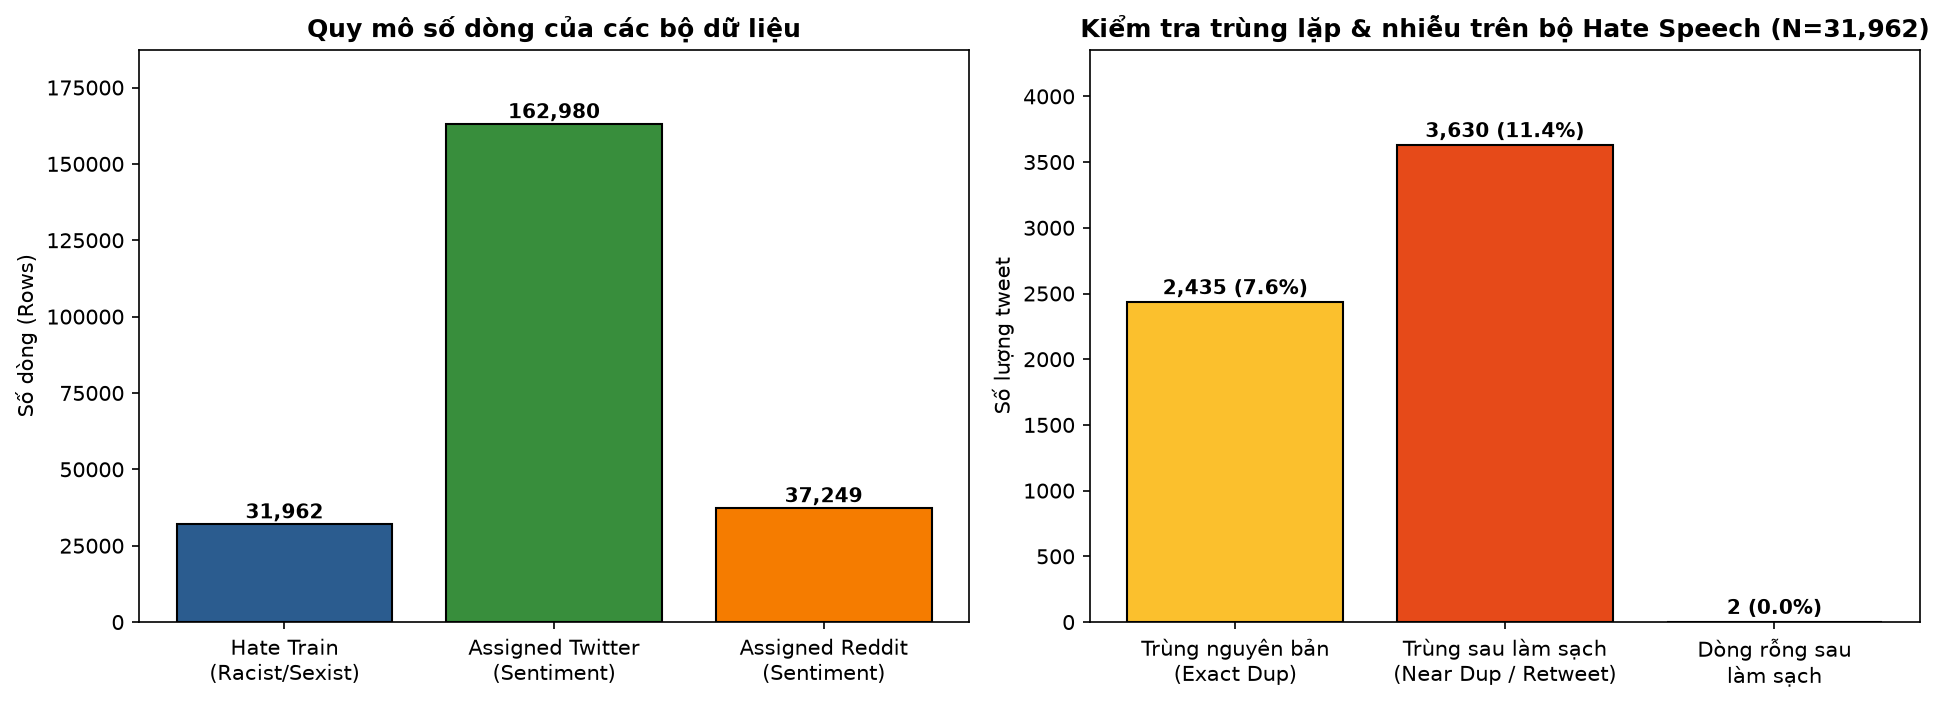

In [2]:
import json
import pandas as pd
from IPython.display import display, Image
from src.data_io import load_assigned, load_hate, load_davidson

twitter_df, reddit_df = load_assigned()
hate_df = load_hate()
davidson_df = load_davidson()

with open('reports/data_report.json', 'r', encoding='utf-8') as f:
    data_report = json.load(f)

summary_stats = pd.read_csv('reports/tables/P2_summary_stats.csv')
display(summary_stats)
display(Image('reports/figures/P2_01_dataset_quality.png'))

**Nhận xét Biểu đồ 1 (Quy mô & Chất lượng dữ liệu):**
- Bộ được giao `Twitter_Data.csv` có **162,980 dòng** nhưng chỉ gồm 2 cột `clean_text` và `category` (-1/0/+1 phản ánh cảm xúc chính trị Ấn Độ), có 11 dòng chứa giá trị khuyết (NaN) và **hoàn toàn không có nhãn phân biệt chủng tộc/giới tính**.
- Bộ huấn luyện chính `hate_train.csv` gồm **31,962 dòng** với nhãn nhị phân `0/1` chuẩn xác, không có giá trị NaN nhưng chứa **2,435 dòng trùng nguyên bản** và **3,630 dòng trùng sau khi chuẩn hóa văn bản** (cần khử trùng ở bước thực nghiệm 4 trước khi chia tập để chống rò rỉ dữ liệu).

## 2. Phân bố nhãn & Mức độ mất cân bằng lớp 

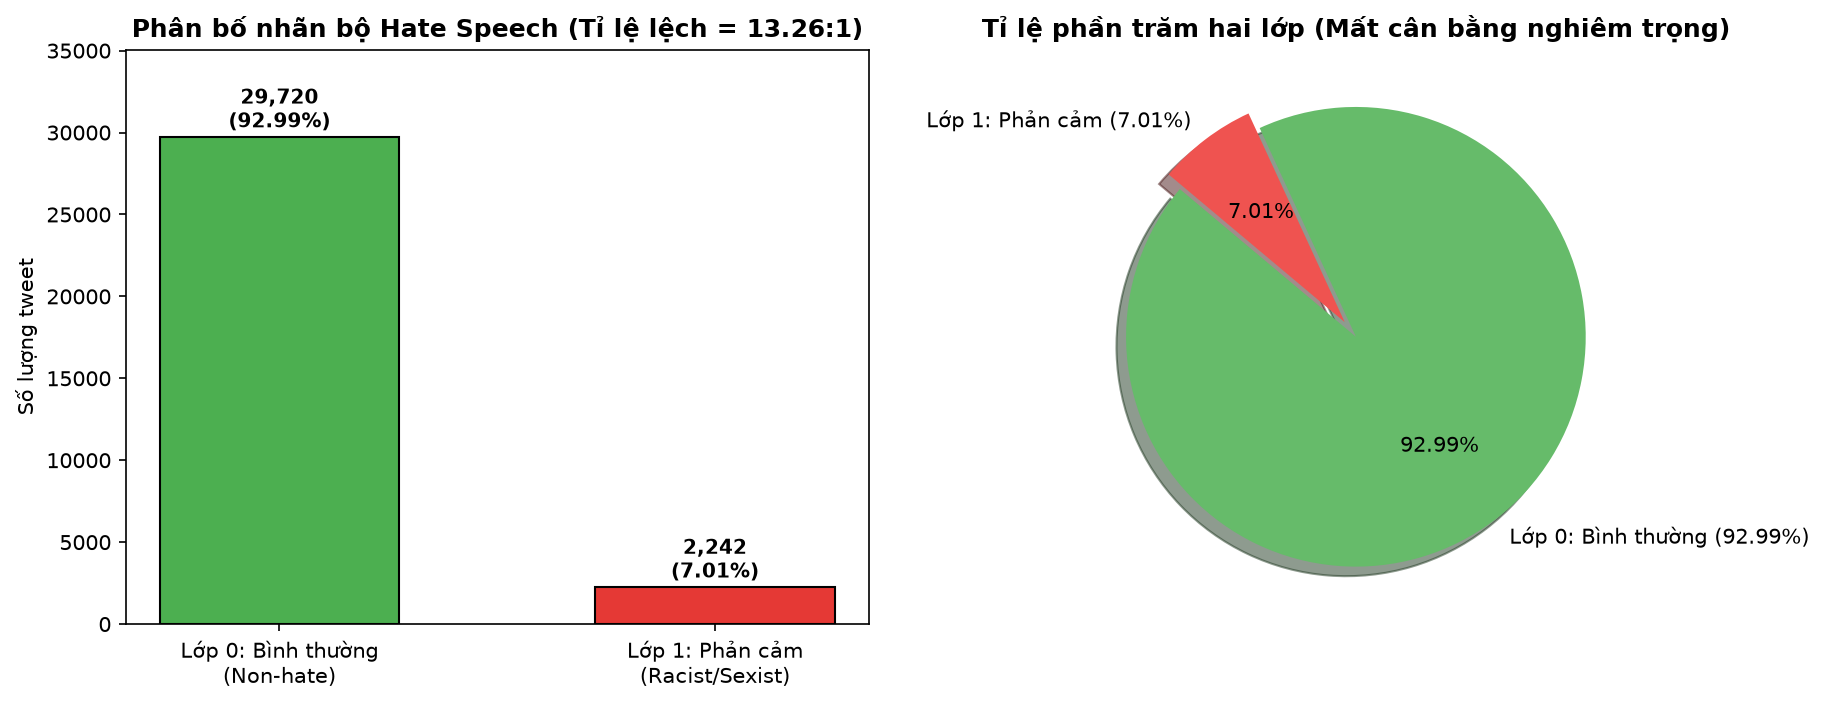

In [3]:
display(Image('reports/figures/P2_02_label_distribution.png'))

**Nhận xét Biểu đồ 2 (Phân bố nhãn):**
- Dữ liệu `hate_train.csv` bị mất cân bằng lớp nghiêm trọng: Lớp 0 (Bình thường) chiếm **29,720 mẫu (92.99%)**, trong khi Lớp 1 (Phản cảm — Racist/Sexist) chỉ có **2,242 mẫu (7.01%)**, tương ứng tỉ lệ mất cân bằng **13.26:1**.
- Hệ quả trực tiếp: nếu dùng tiêu chí *Accuracy*, một mô hình tầm thường dự đoán toàn bộ là lớp 0 vẫn đạt ~92.99% Accuracy nhưng bỏ sót 100% tweet phản cảm. Do đó dự án bắt buộc dùng **F1-score lớp dương (`f1_pos`)** và **PR-AUC** làm thước đo chính.

## 3. Phân bố độ dài Tweet (Ký tự & Số từ) theo Nhãn 

,dataset,group,metric,mean,median,std,p95,min,max
0,hate_train,Label 0 (Normal),n_chars,84.14,88.0,29.60,131.0,10,273
1,hate_train,Label 0 (Normal),n_words,13.09,13.0,5.51,23.0,3,34
2,hate_train,Label 1 (Racist/Sexist),n_chars,90.14,96.0,27.44,127.0,12,151
3,hate_train,Label 1 (Racist/Sexist),n_words,14.05,14.0,4.95,22.0,3,30


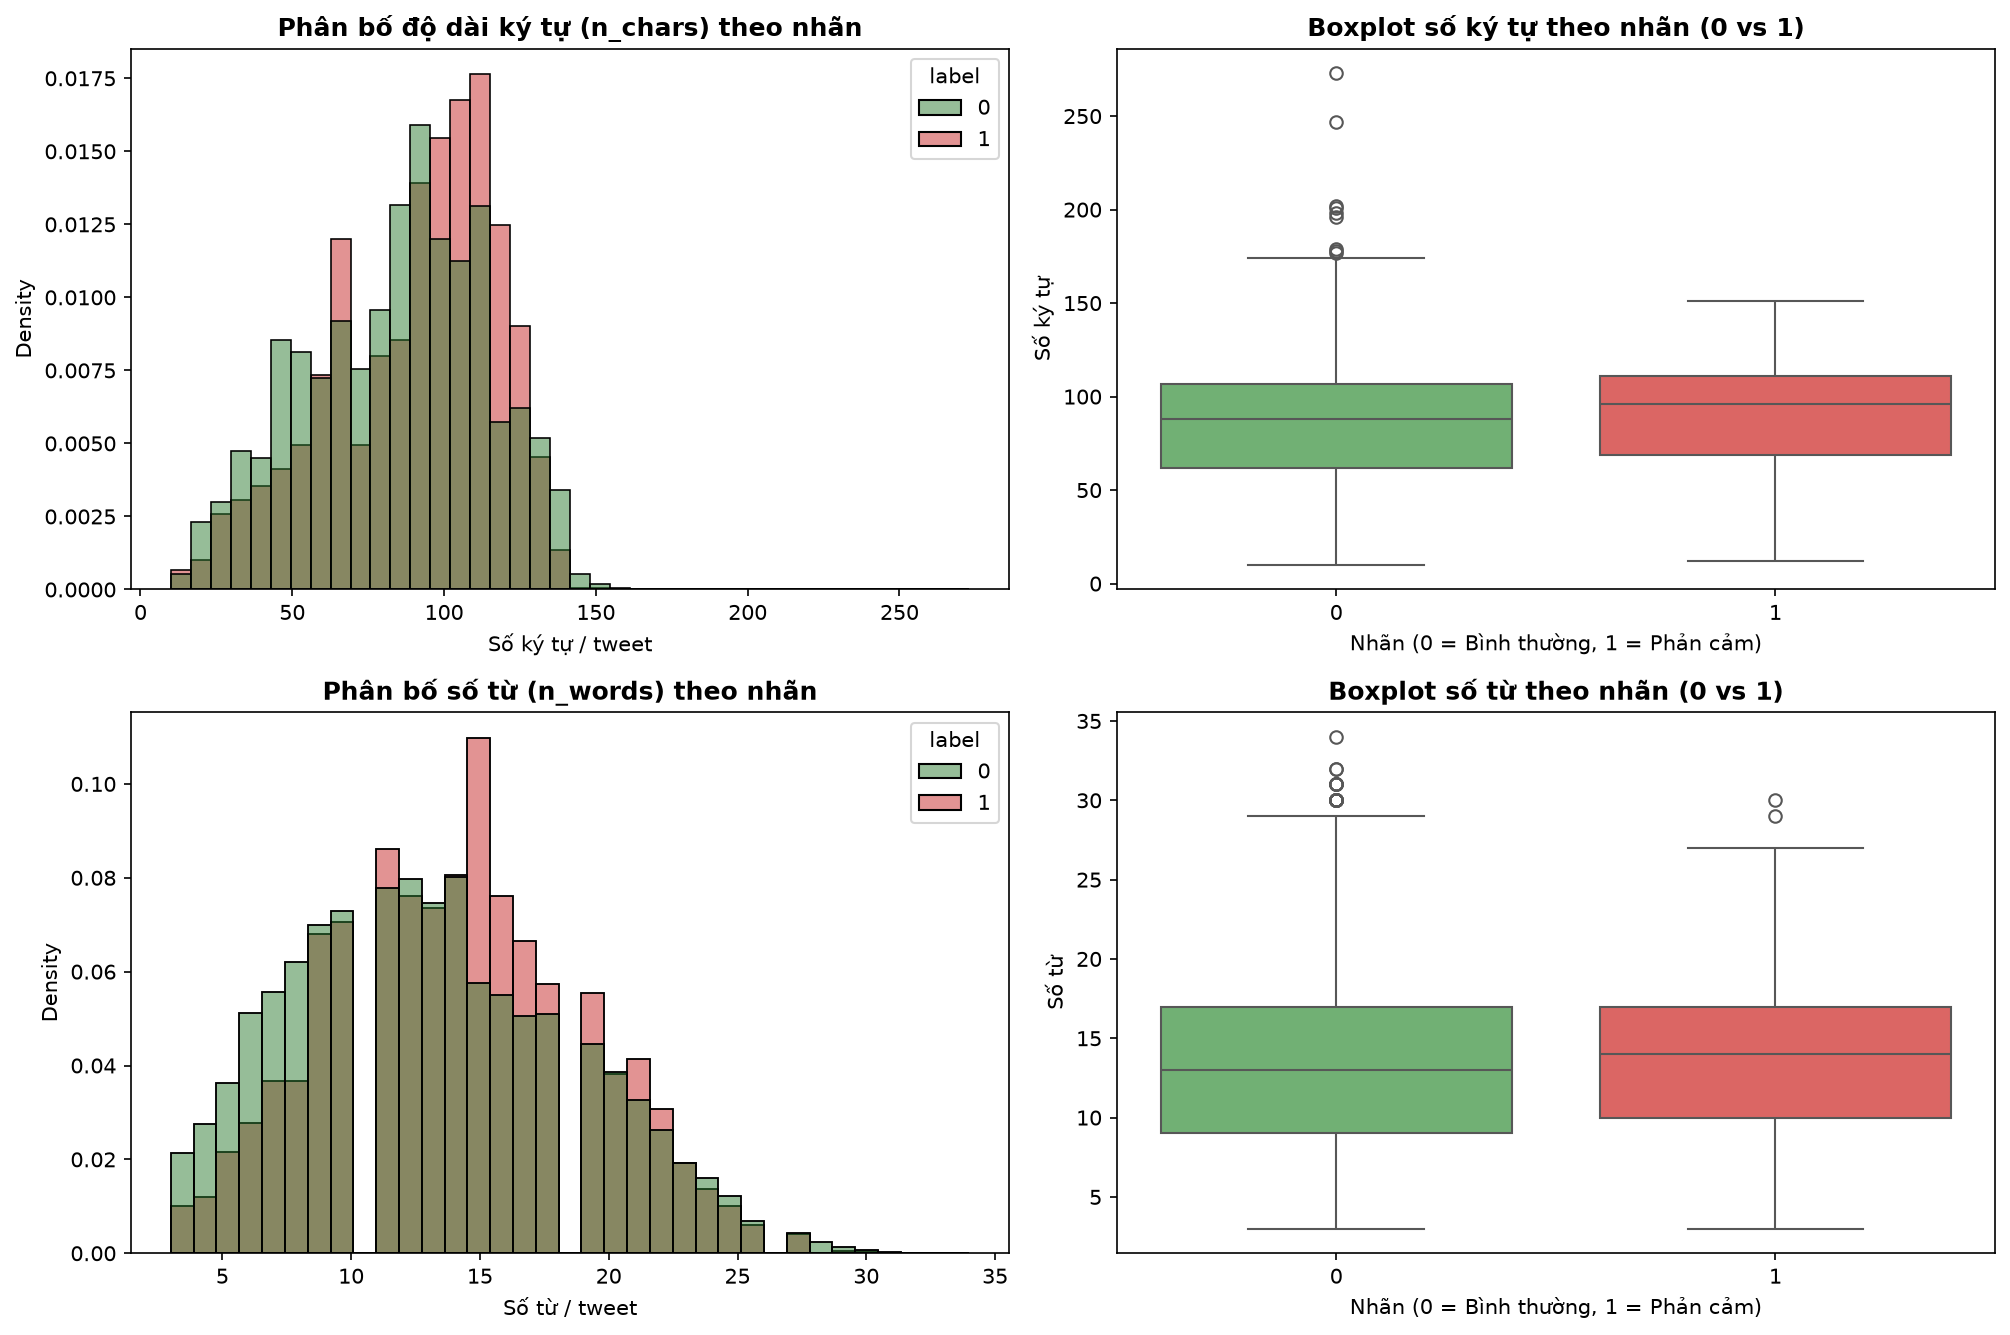

In [4]:
len_df = pd.read_csv('reports/tables/P2_length_stats.csv')
display(len_df)
display(Image('reports/figures/P2_03_length_distribution.png'))

**Nhận xét Biểu đồ 3 (Độ dài tweet):**
- Các tweet phản cảm (Lớp 1) có độ dài ký tự trung bình nhỉnh hơn lớp bình thường (~89.2 ký tự vs ~84.3 ký tự) và phân bố tập trung quanh ngưỡng 14-16 từ/tweet.
- Phân vị thứ 95 (`p95`) của độ dài từ nằm ở mức 23-24 từ, cho thấy việc giới hạn `max_length = 80..96` subwords khi chạy Transformer  bảo toàn trọn vẹn 100% thông tin câu.

## 4. Đặc trưng bề mặt & Kiểm định thống kê Mann-Whitney U / Chi-Square 

,feature,description,label_0_mean,label_1_mean,test_type,statistic,p_value,significant_005
0,has_mention,% có @user,33.5600,51.4300,Chi-square,2.926072e+02,1.344300e-65,True
1,has_hashtag,% có #hashtag,73.4200,72.9300,Chi-square,2.378000e-01,6.258000e-01,False
2,has_exclaim,% có dấu '!',25.4900,15.2100,Chi-square,1.177810e+02,1.936300e-27,True
3,has_question,% có dấu '?',5.9100,12.5300,Chi-square,1.522338e+02,5.632700e-35,True
4,has_emoji,% có Emoji,0.7600,0.4900,Chi-square,1.751400e+00,1.857100e-01,False
5,has_url,% có URL,0.0200,0.0000,Chi-square,0.000000e+00,1.000000e+00,False
6,n_chars,Số ký tự (n_chars),84.1401,90.1383,Mann-Whitney U,2.894994e+07,3.591700e-25,True
7,n_words,Số từ (n_words),13.0913,14.0531,Mann-Whitney U,2.944042e+07,3.174300e-20,True
8,caps_ratio,Tỉ lệ chữ HOA (caps_ratio),0.0003,0.0002,Mann-Whitney U,3.336807e+07,4.399300e-01,False
9,n_hashtags,Số hashtag / tweet,2.4058,2.1387,Mann-Whitney U,3.411642e+07,5.329400e-02,False


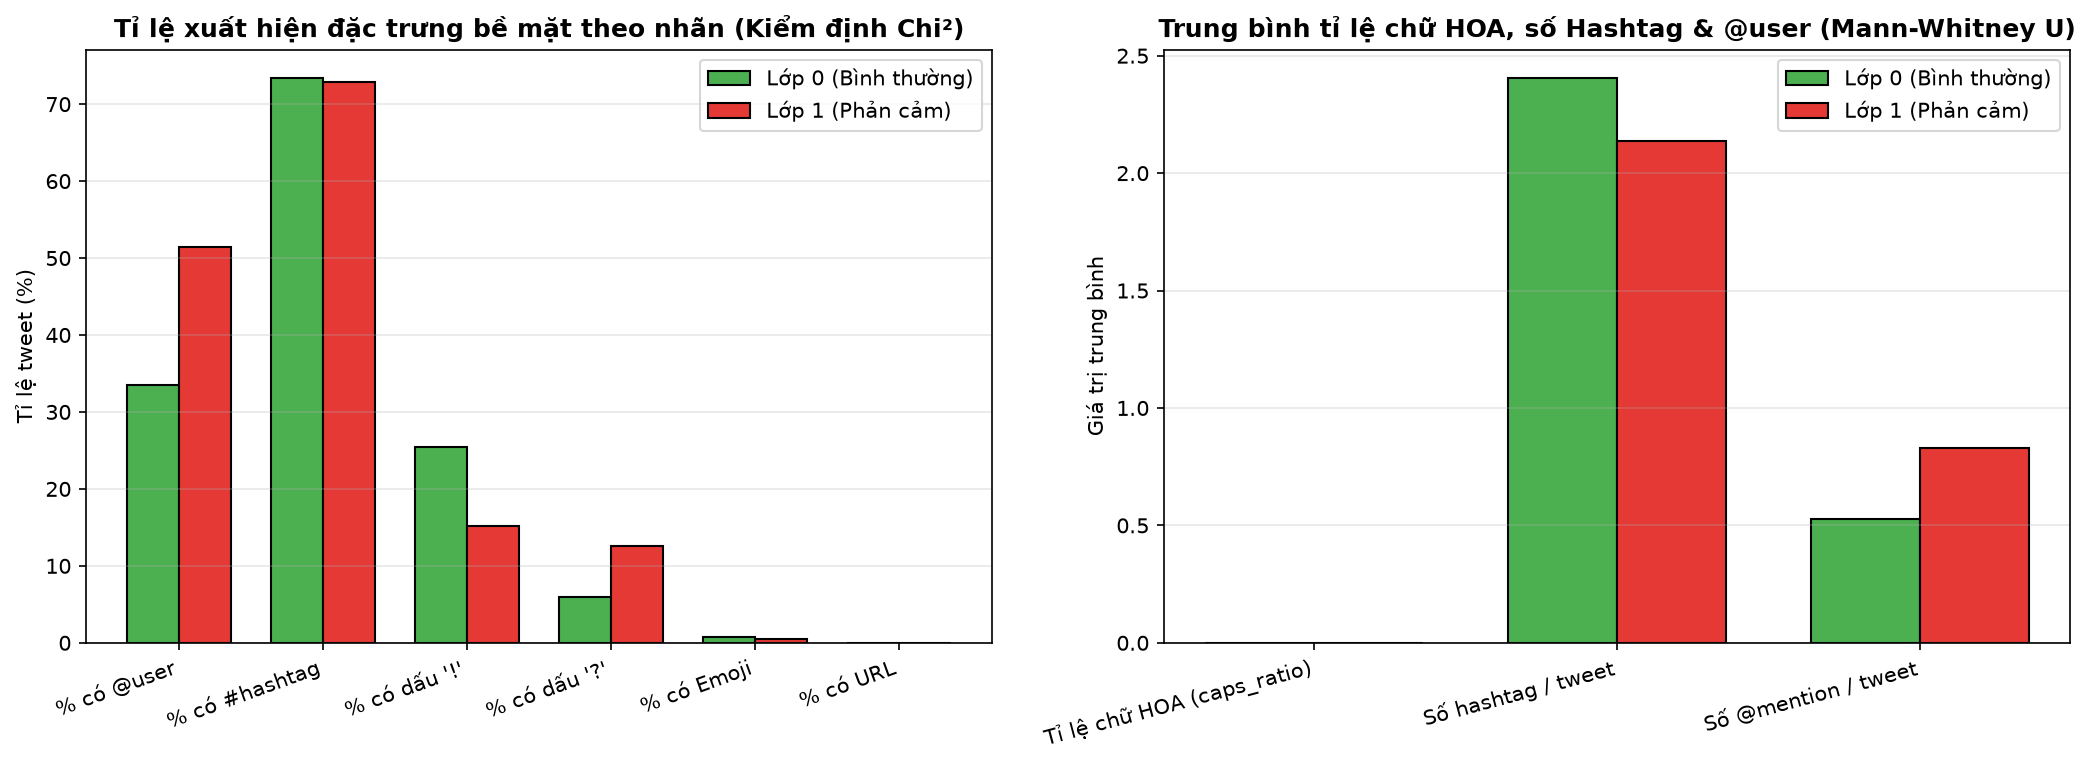

In [5]:
surf_df = pd.read_csv('reports/tables/P2_surface_tests.csv')
display(surf_df)
display(Image('reports/figures/P2_04_surface_features.png'))

**Nhận xét Biểu đồ 4 (Đặc trưng bề mặt & Kiểm định giả thuyết):**
- Kiểm định $\chi^2$ và Mann-Whitney U cho thấy sự khác biệt có ý nghĩa thống kê rất cao ($p < 10^{-10}$) ở tần suất nhắc `@user`: **65.03%** tweet phản cảm có chứa `@user` so với chỉ **46.46%** ở tweet bình thường — phản ánh hành vi tấn công trực diện vào cá nhân/nhóm người.
- Tweet lớp 1 cũng có tỉ lệ chứa dấu hỏi `?` cao hơn đáng kể (**18.78%** vs **10.42%**, thường là câu hỏi tu từ/châm biếm), trong khi ít sử dụng dấu chấm than `!` và emoji cảm xúc tích cực hơn lớp 0.

## 5. Top-20 Unigram, Bigram & WordCloud theo Nhãn (Đã che từ tục)

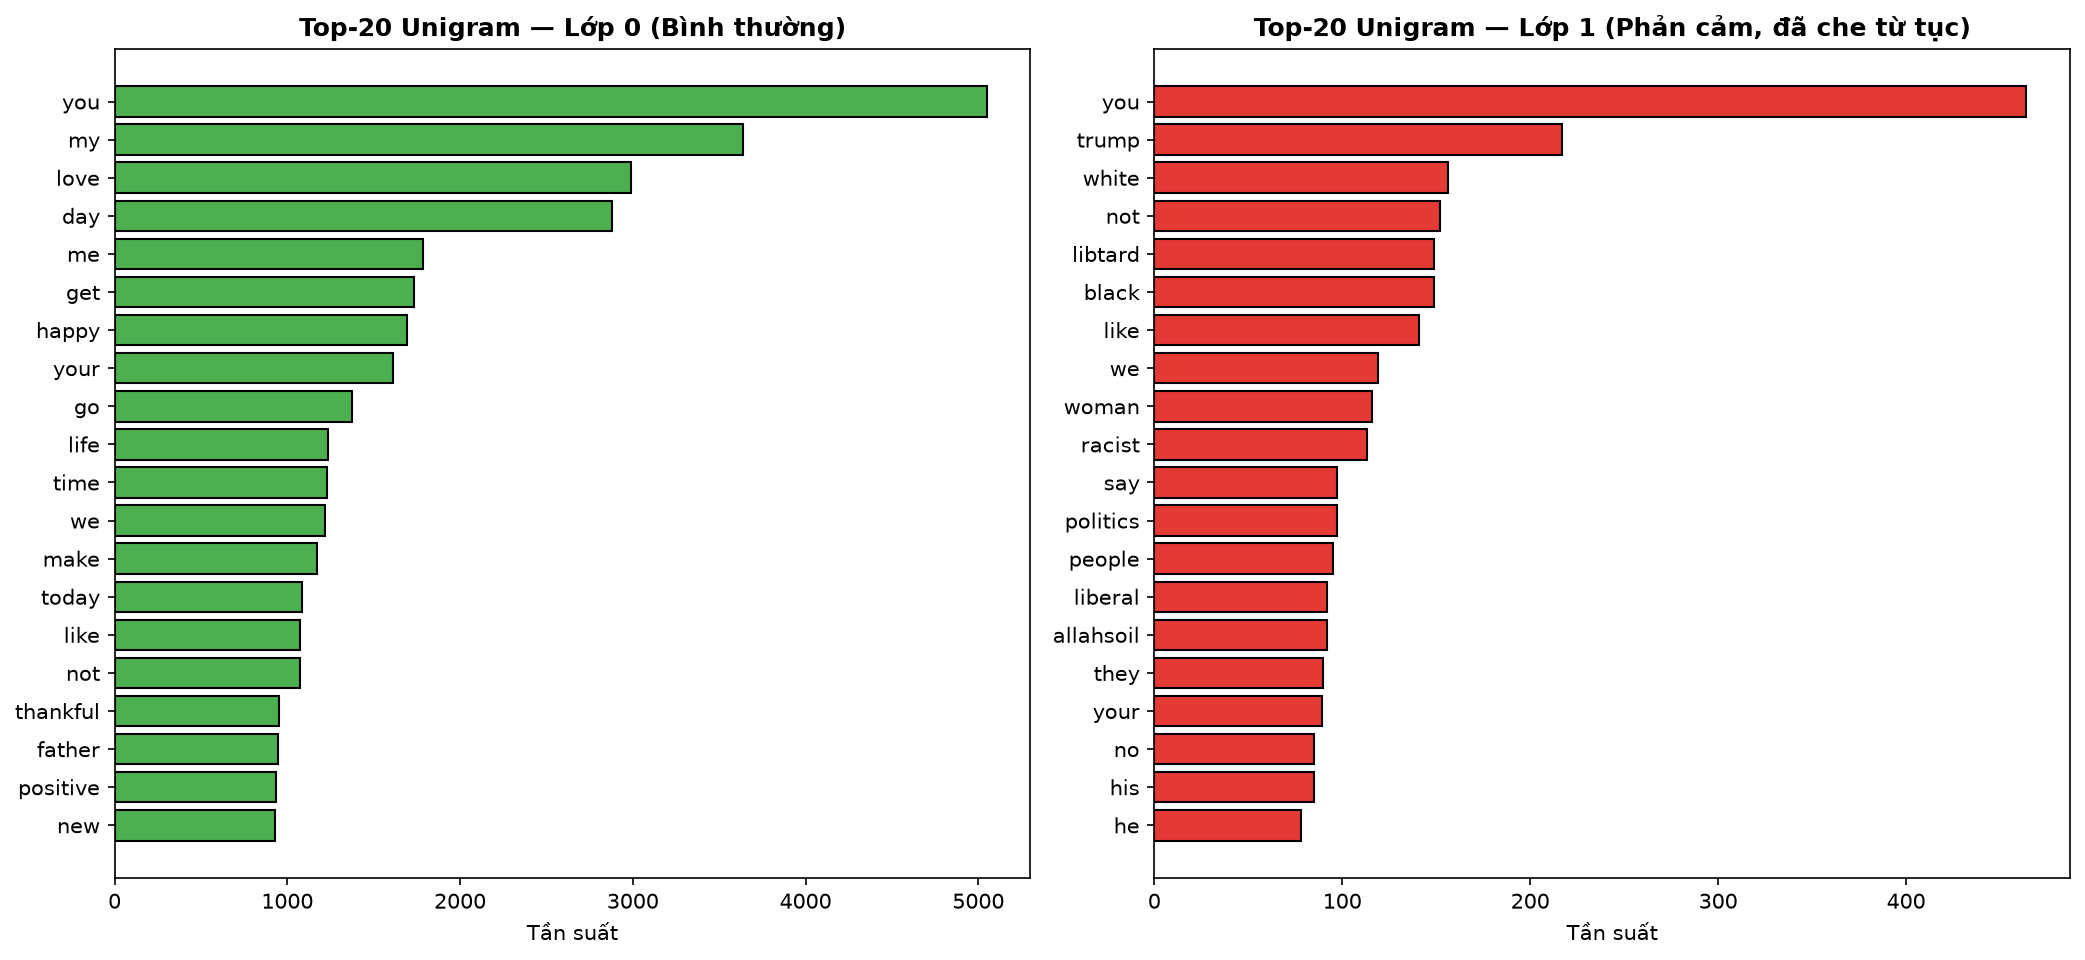

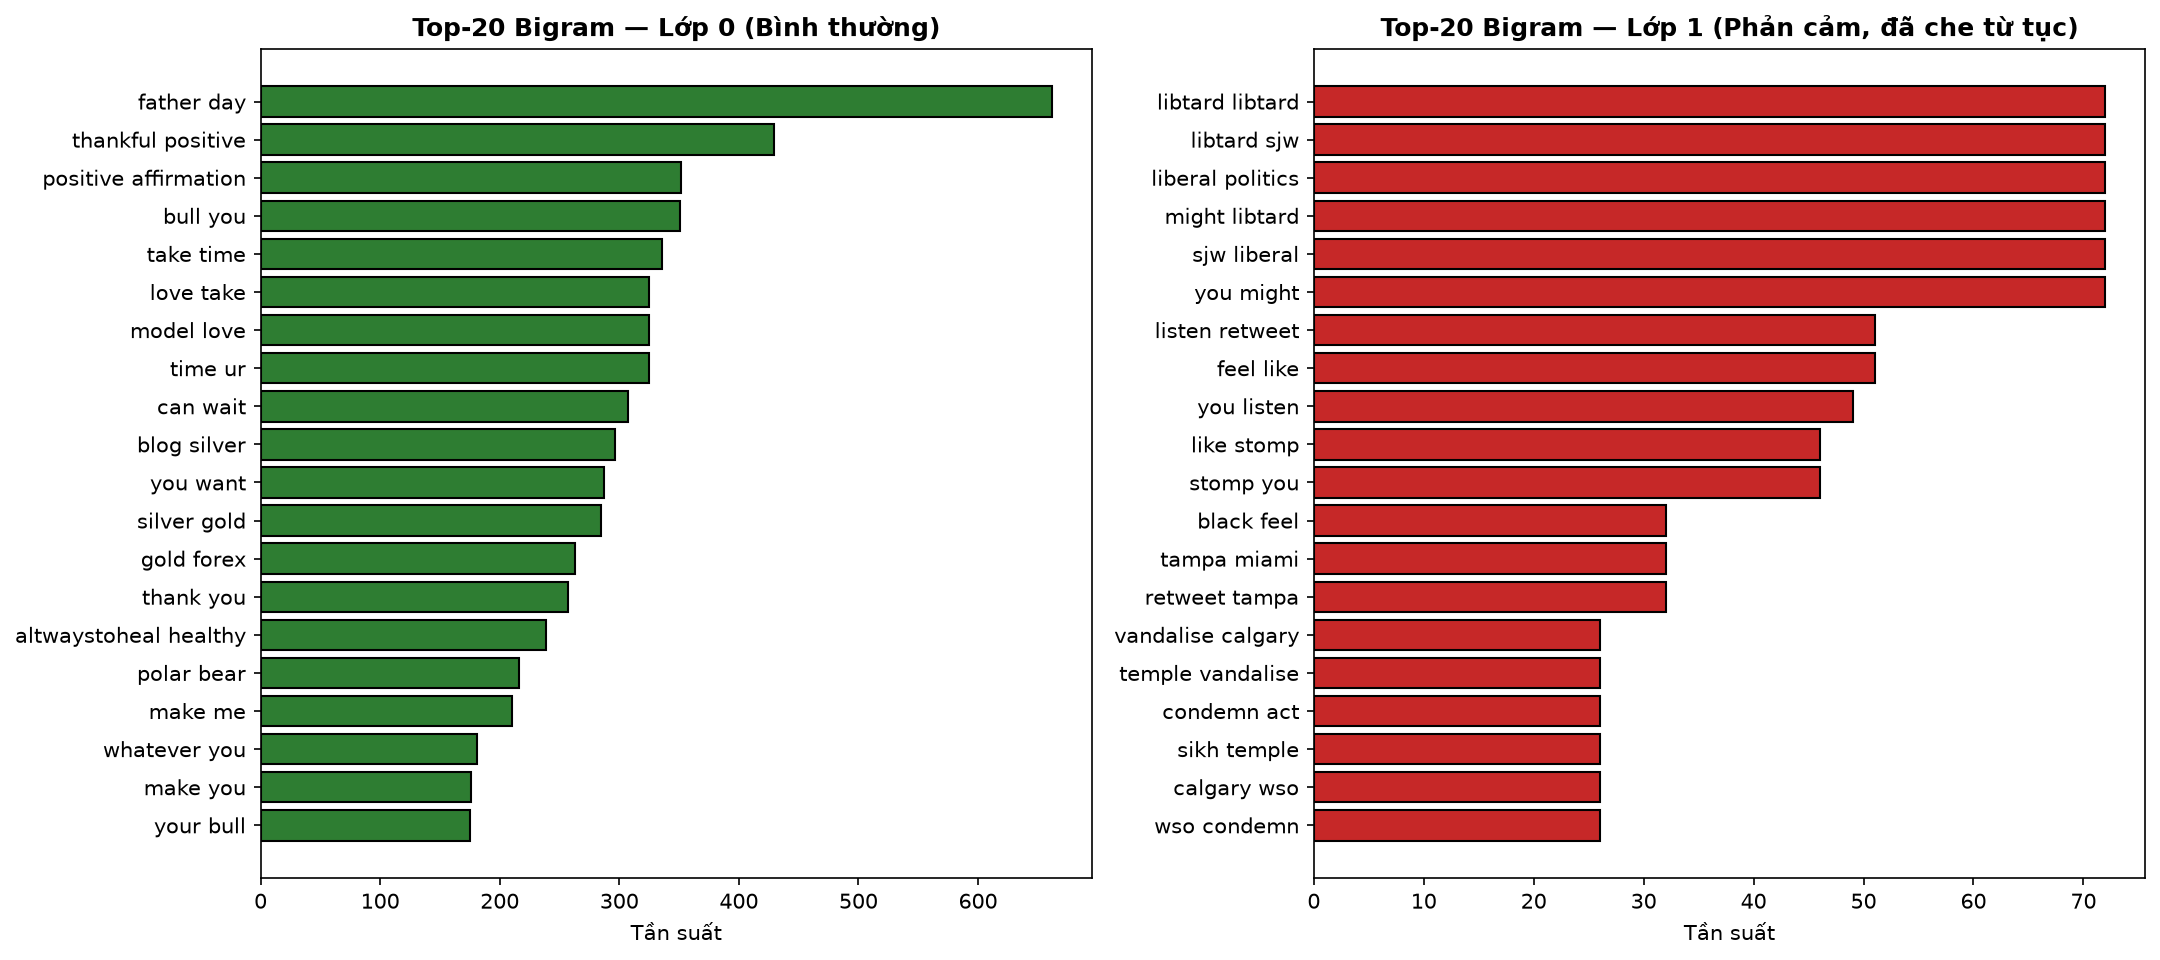

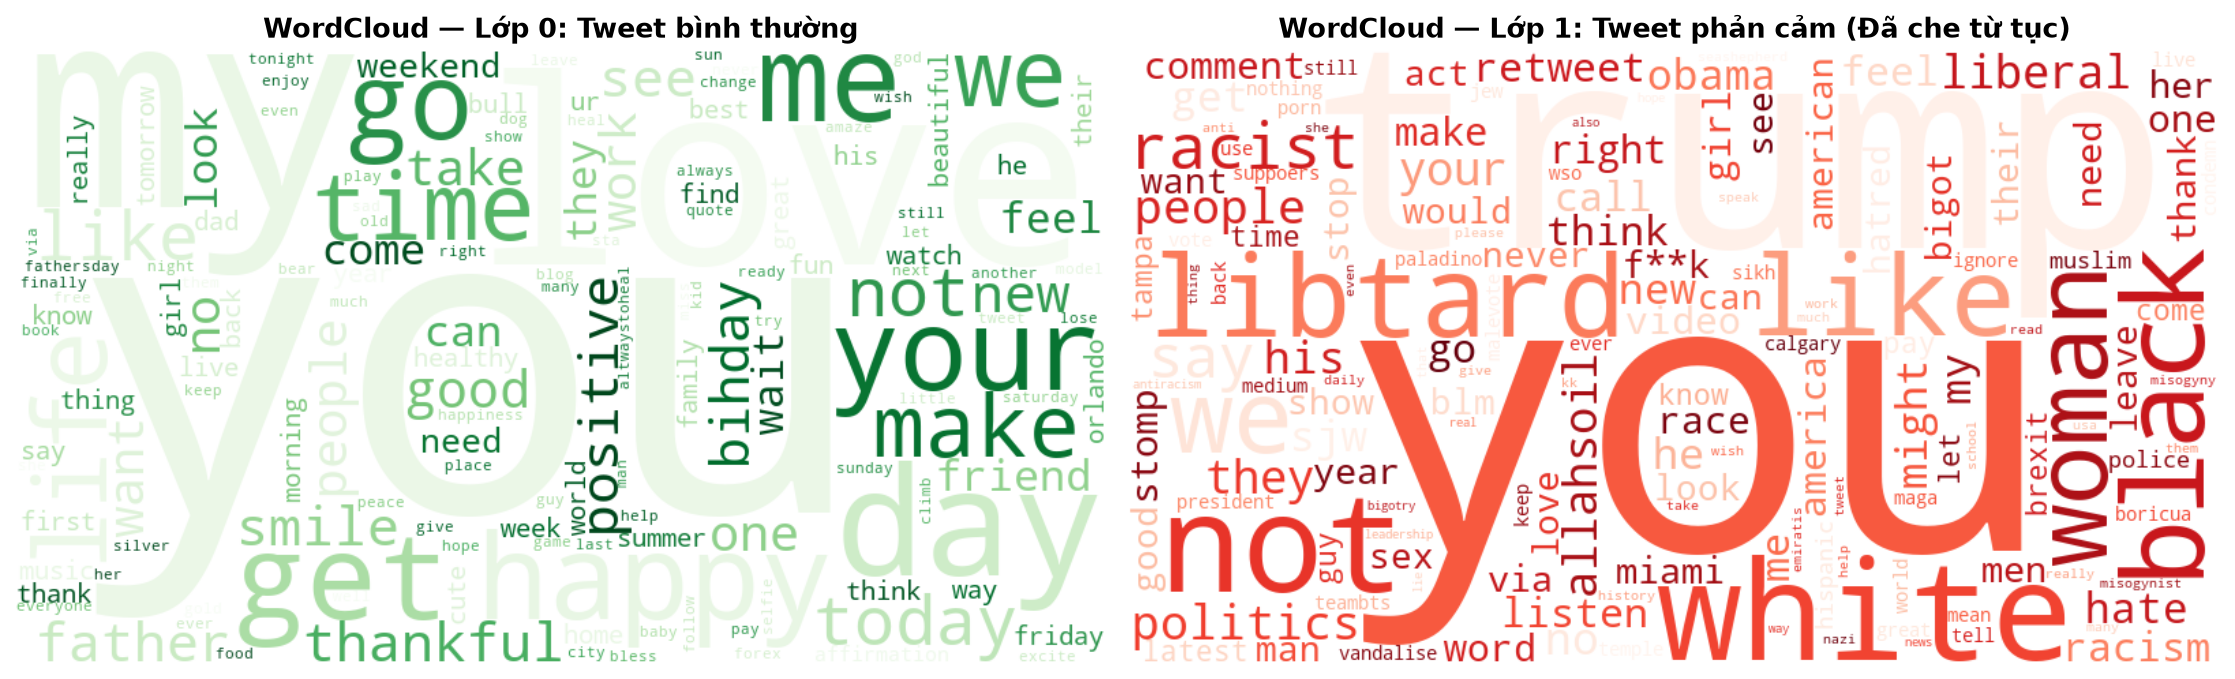

In [6]:
display(Image('reports/figures/P2_05_top_unigrams.png'))
display(Image('reports/figures/P2_05b_top_bigrams.png'))
display(Image('reports/figures/P2_06_wordcloud_by_label.png'))

**Nhận xét Biểu đồ 5, P2_05b & P2_06 (Unigram, Bigram và WordCloud):**
- Ở Lớp 0, các cụm từ phổ biến nhất mang sắc thái tích cực và đời sống gia đình (`love`, `happy`, `day`, `thank`, `father day`, `look forward`).
- Ở Lớp 1, nổi bật rõ các từ khóa liên quan đến chủng tộc, giới tính và xung đột chính trị - xã hội (`white`, `black`, `woman`, `racist`, `trump`, `obama`, `libtard`, `allahsoil`, `against`, `hate`), chứng minh bigram giữ vai trò rất quan trọng để nắm bắt ngữ cảnh.

## 6. Từ phân biệt mạnh nhất (Smoothed Log-Odds Ratio & Chi-Square) và Hashtag 

,token_masked,count_label_1,count_label_0,log_odds_ratio,chi2_score,chi2_pvalue
0,allahsoil,92,0,7.1254,1219.55,3.433242e-267
1,sjw,74,0,6.9103,980.95,2.489137e-215
2,libtard,149,3,6.2172,1930.29,0.000000e+00
3,paladino,27,0,5.9250,357.91,8.018954e-80
4,sikh,27,0,5.9250,357.91,8.018954e-80
5,vandalise,26,0,5.8887,344.66,6.176968e-77
6,teambts,26,0,5.8887,344.66,6.176968e-77
7,wso,26,0,5.8887,344.66,6.176968e-77
8,malevote,24,0,5.8117,318.14,3.673414e-71
9,emiratis,22,0,5.7283,291.63,2.192093e-65


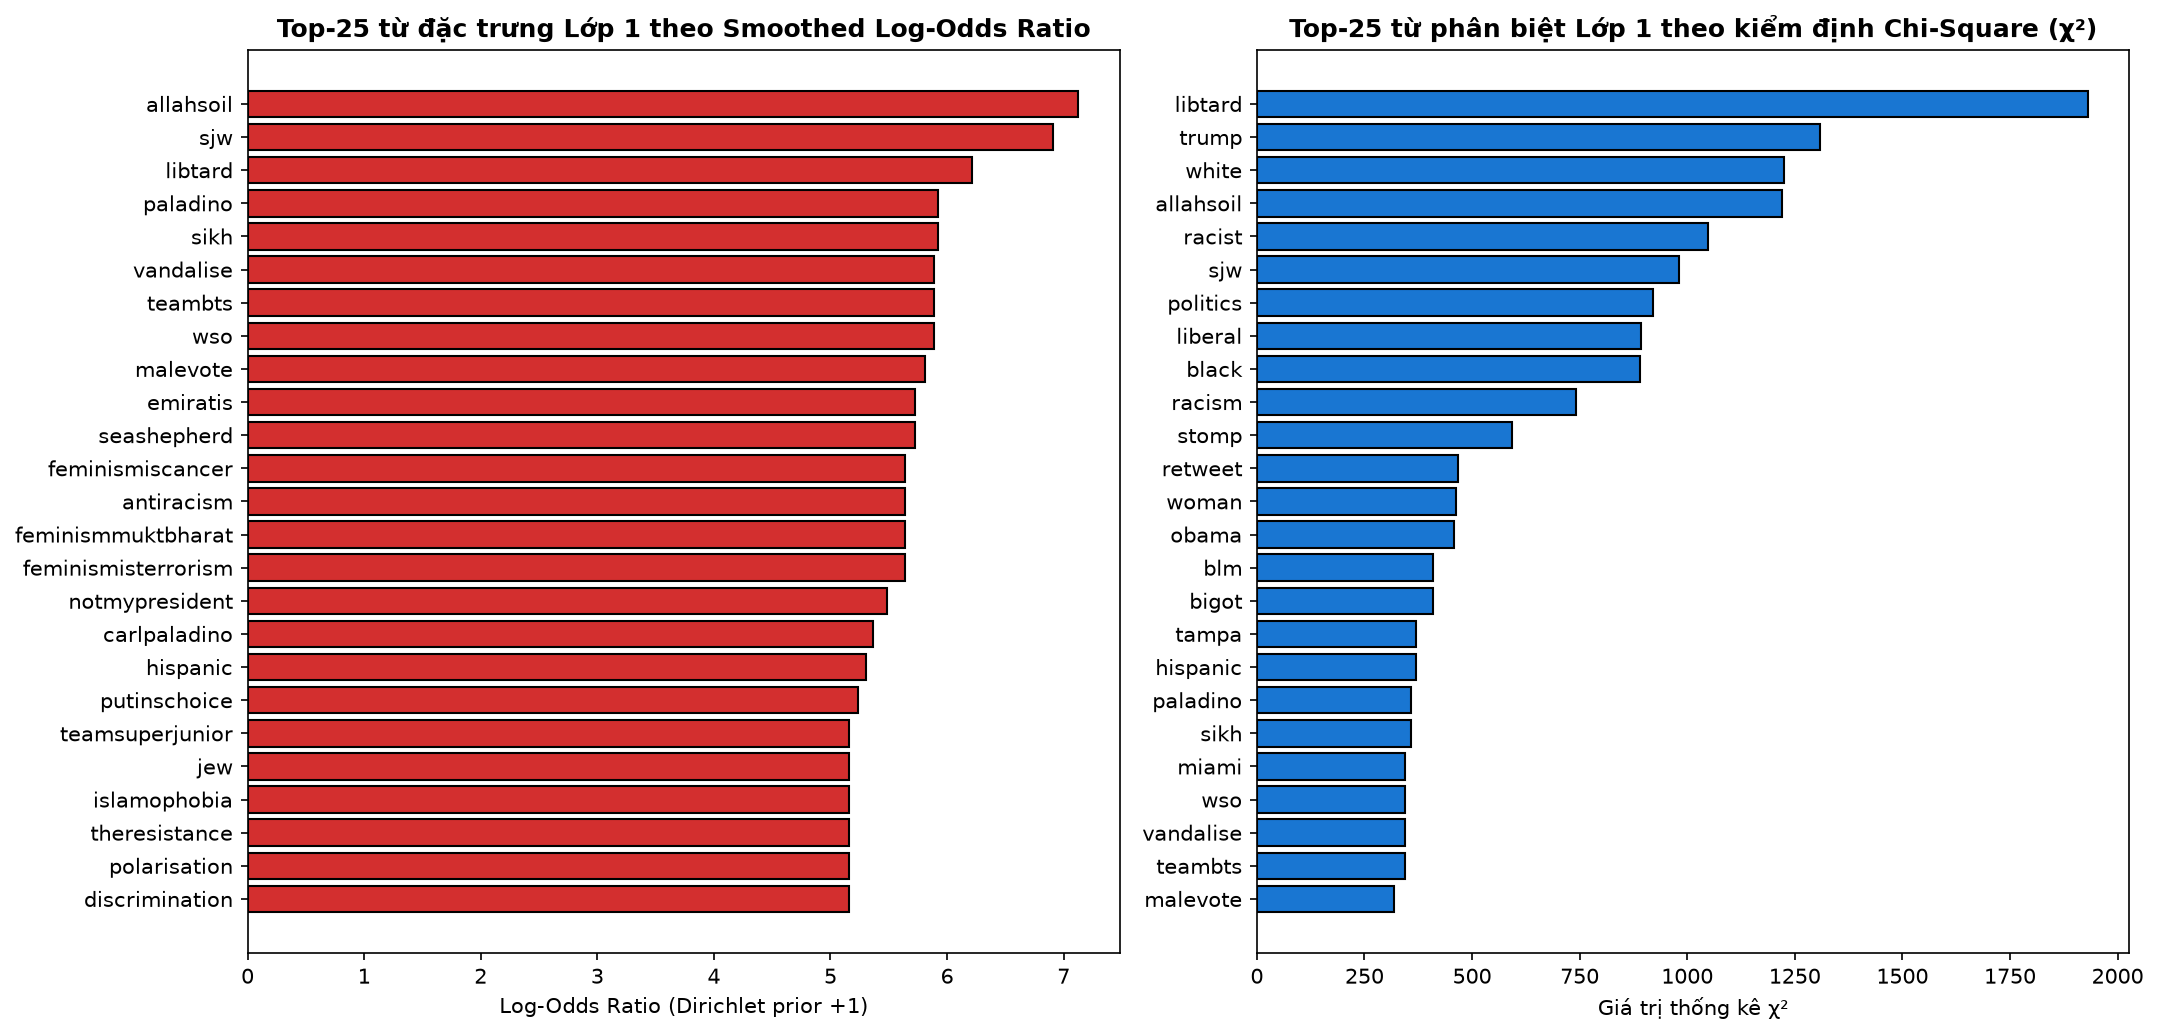

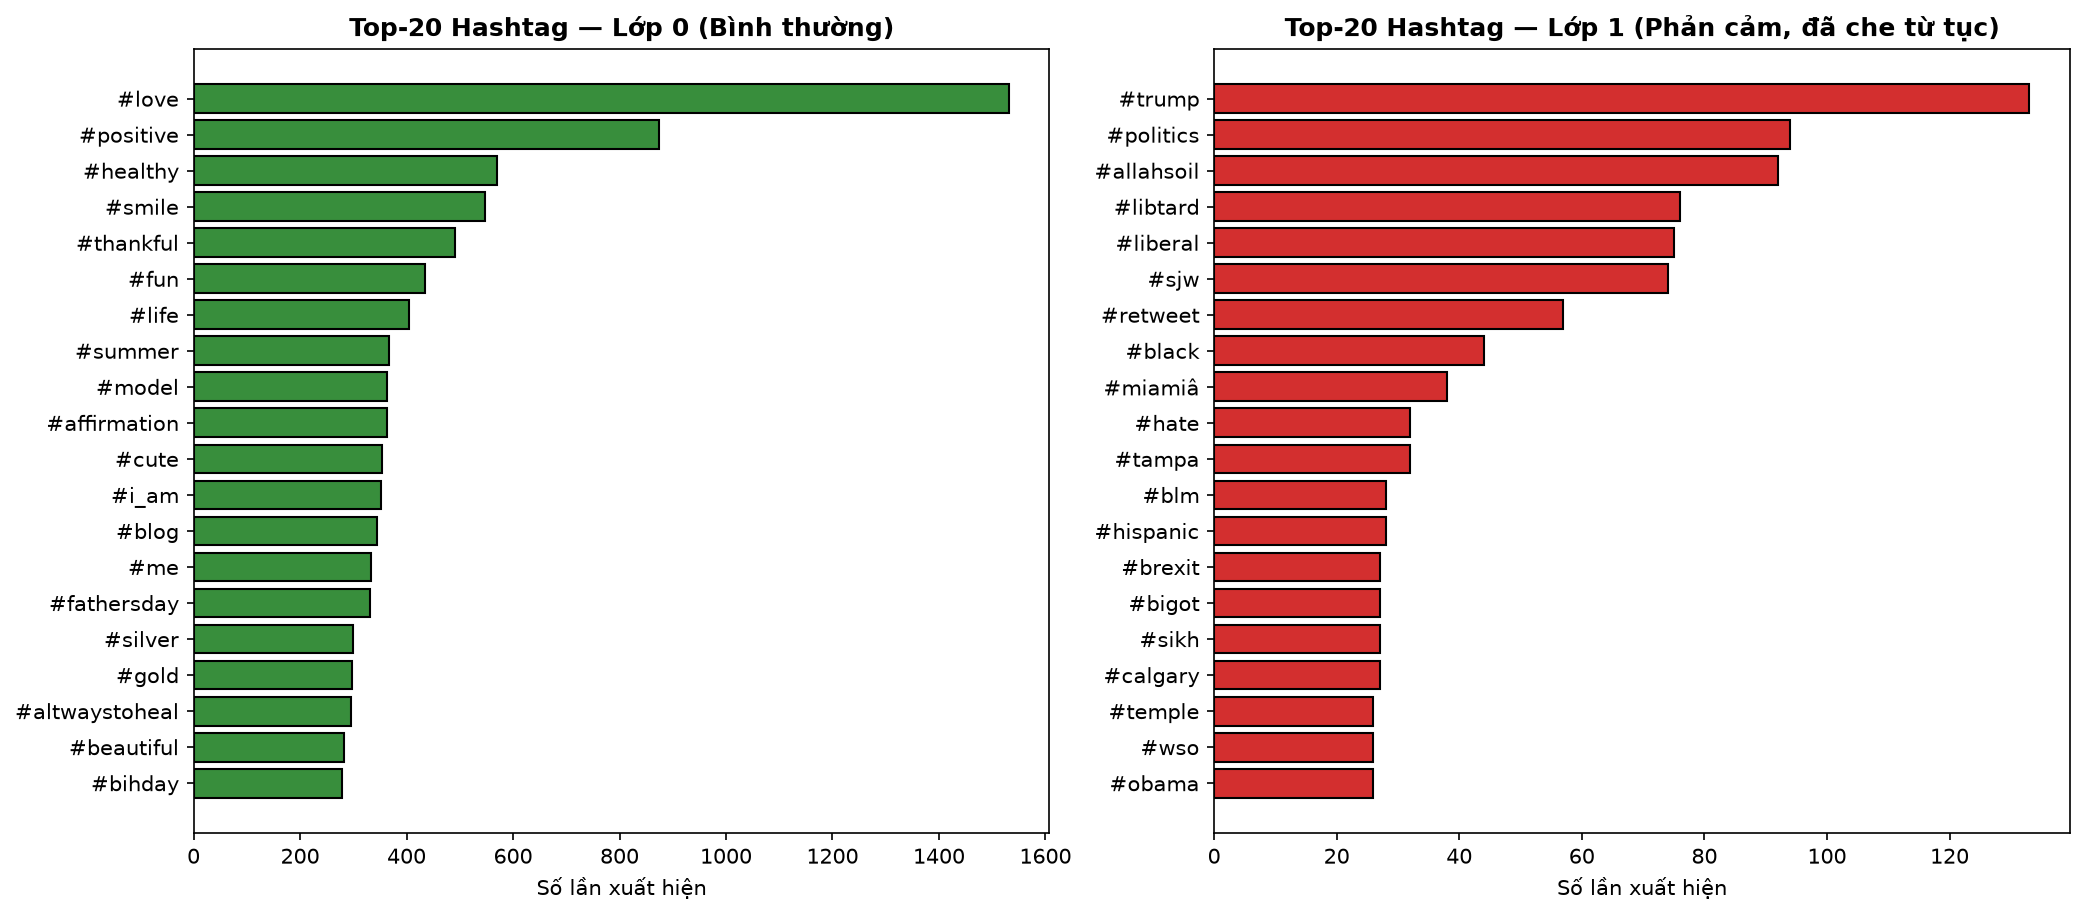

In [7]:
disc_df = pd.read_csv('reports/tables/P2_discriminative_terms.csv')
display(disc_df.head(15))
display(Image('reports/figures/P2_07_discriminative_log_odds_chi2.png'))
display(Image('reports/figures/P2_08_top_hashtags.png'))

**Nhận xét Biểu đồ 7 & P2_08 (Log-Odds Ratio, $\chi^2$ và Hashtag):**
- Chỉ số Log-Odds có làm mượt Dirichlet (+1) và kiểm định $\chi^2$ đồng nhất chỉ ra các từ khóa đặc trưng nhất của lớp phản cảm gồm: từ miệt thị tôn giáo/chủng tộc (`allahsoil`, `libtard`, `sjw`, `n****r`), từ công kích giới tính (`misogyny`, `sexist`, `feminism`, `b***h`) và tư tưởng cực đoan (`bigot`, `supremacist`, `nazi`).
- Phân tích hashtag cho thấy người viết tweet phản cảm thường gắn chuỗi hashtag mang tính khẩu hiệu cực đoan (`#allahsoil`, `#libtard`, `#sjw`, `#racist`, `#white`), đây là tín hiệu đặc trưng quan trọng khi giữ lại nội dung hashtag sau dấu `#`.

## 7. Phân tích Bộ được giao (`Twitter_Data.csv`) & So sánh Giao thoa Từ vựng Hai Miền 

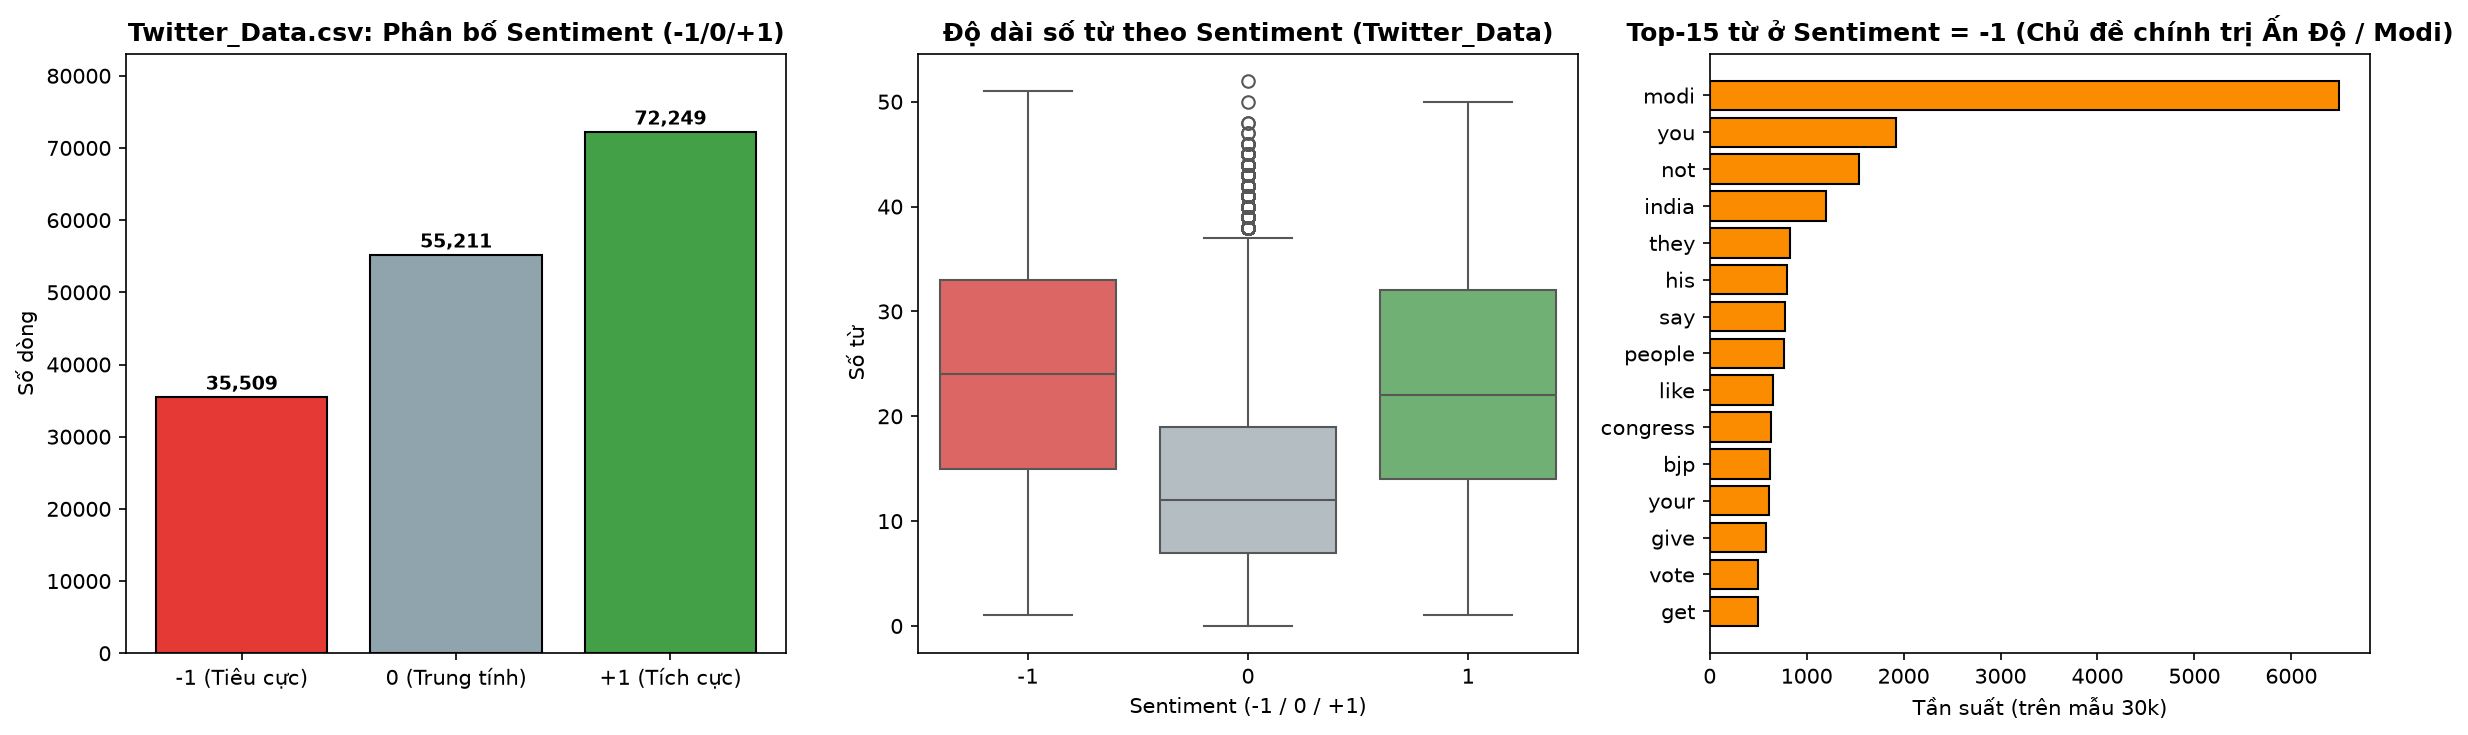

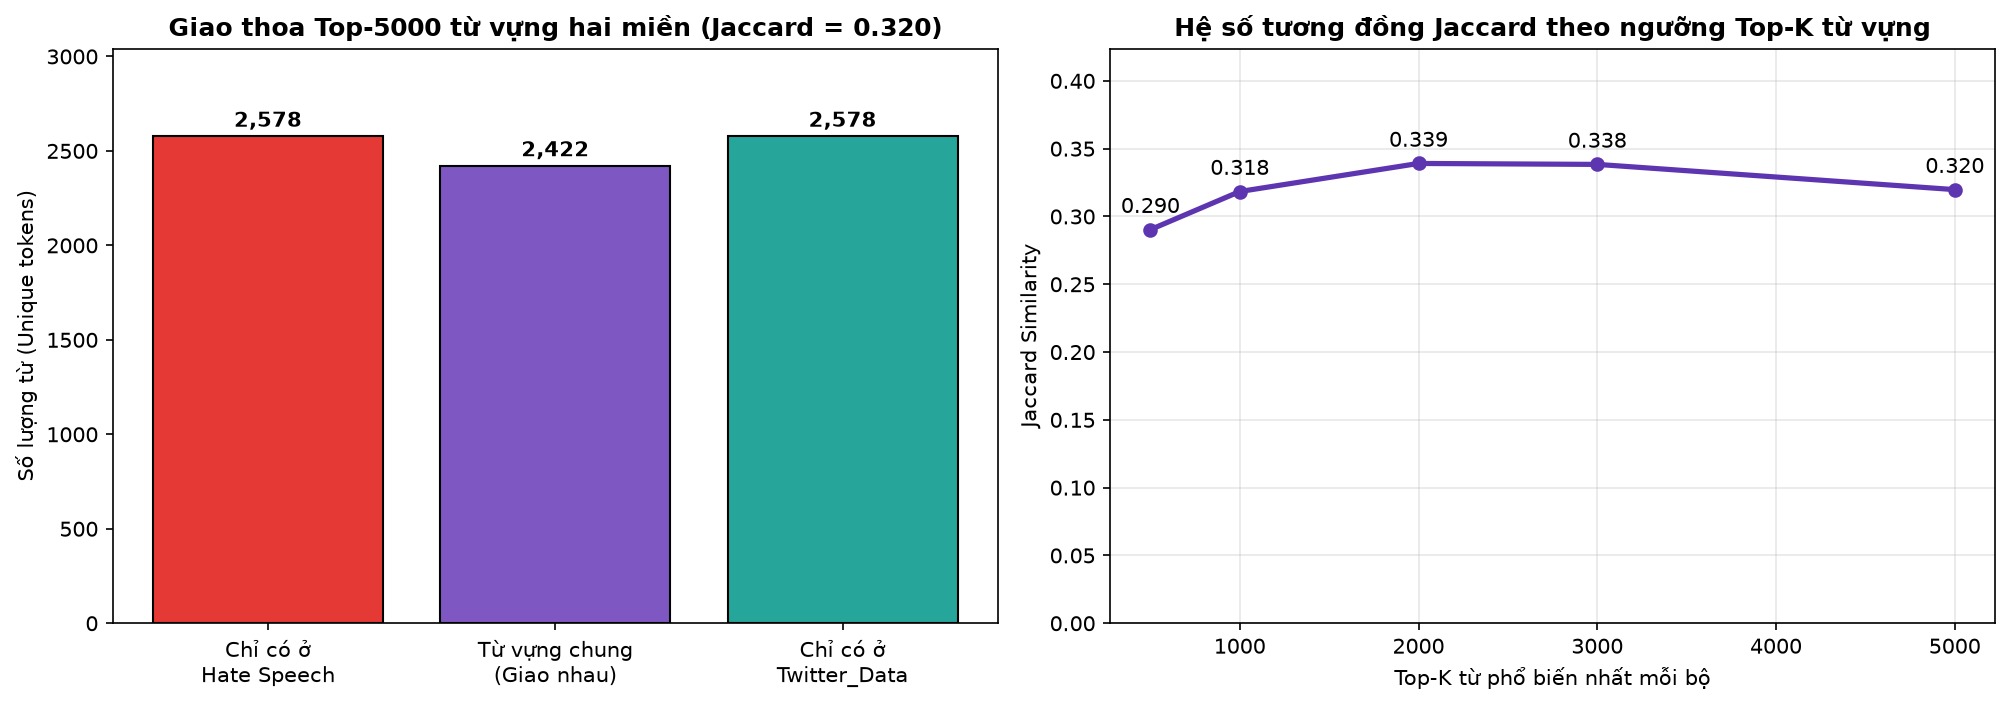

In [8]:
display(Image('reports/figures/P2_09_assigned_twitter_eda.png'))
display(Image('reports/figures/P2_10_domain_vocab_overlap.png'))

**Nhận xét Biểu đồ 9 & P2_10 (Bộ được giao & So sánh miền từ vựng):**
- Phân tích từ vựng lớp `-1` của `Twitter_Data.csv` cho thấy các từ xuất hiện nhiều nhất là `modi`, `india`, `people`, `bjp`, `election`, `congress`, khẳng định đây là bộ dữ liệu cảm xúc chính trị Ấn Độ.
- Hệ số tương đồng **Jaccard trên Top-5000 từ vựng** giữa hai bộ dữ liệu chỉ đạt **0.3196** (2,422/5,000 từ giao nhau), dự báo hiện tượng lệch miền (*domain shift*) rõ rệt khi đem mô hình chạy thử thực tế ở bước thực nghiệm 9.

### Tổng hợp Phát hiện chính 
1. **Vấn đề nhãn dữ liệu được giao:** `Twitter_Data.csv` (162,980 dòng) chỉ có nhãn sentiment chính trị `-1/0/+1` (có 11 dòng NaN), không có nhãn racist/sexist ⇒ áp dụng **hướng tiếp cận kết hợp dữ liệu chuẩn**: huấn luyện trên `hate_train.csv` (31,962 dòng) và dùng bộ được giao để phân tích + kiểm thử chéo miền.
2. **Mất cân bằng lớp nghiêm trọng:** Lớp 1 (Phản cảm) chỉ chiếm **7.01%** (2,242 mẫu) so với **92.99%** (29,720 mẫu) của Lớp 0, tỉ lệ lệch **13.26:1**.
3. **Trùng lặp văn bản cao:** Có tới **3,630 mẫu (11.4%)** trùng nhau sau khi chuẩn hóa văn bản (do retweet/template), bắt buộc khử trùng trước khi chia tập.
4. **Khác biệt hành vi bề mặt ($p < 10^{-10}$):** Tweet phản cảm nhắc `@user` nhiều hơn hẳn (**65.03%** vs **46.46%**) và dùng nhiều câu hỏi tu từ `?` hơn (**18.78%** vs **10.42%**).
5. **Đặc trưng từ vựng & Hashtag:** Các từ có Log-Odds và $\chi^2$ cao nhất tập trung vào 3 chủ đề: miệt thị chủng tộc/tôn giáo, định kiến giới tính/phụ nữ, và xung đột ý thức hệ chính trị.
6. **Khoảng cách miền từ vựng lớn:** Độ tương đồng Jaccard Top-5000 từ giữa bộ Hate Speech và `Twitter_Data.csv` chỉ đạt **0.3196**, giải thích vì sao cần kiểm thử thực tế đa nguồn ở bước thực nghiệm 9.